
# **Fine-Tuning BERT: From Full Fine-Tuning to PEFT**

**Objective:** Explore and compare different fine-tuning techniques using BERT for binary sentiment classification.

**Model:** `bert-base-uncased`  
**Dataset:** SST-2 (Stanford Sentiment Treebank)  
**Task:** Classify text as **Positive (1)** or **Negative (0)**.



## **Transformer-based Large Language Models (LLMs)**


<p align="center">
  <img src="https://assets.insightmediagroup.io/media/wp-content/uploads/2024/05/1Qww2aaIdqrWVeNmo3AS0ZQ.png" width="1000">
</p>


### Fine-Tuning Strategies

| Technique | Trainable Parameters |
|---|---|
| Head-Only | Classification head |
| Full Fine-Tuning | Entire BERT + classification head |
| LoRA | Low-rank matrices + classification head |
| Adapters | Bottleneck adapters + classification head |
| Soft Prompt Tuning | Learnable prompt embeddings + classification head |

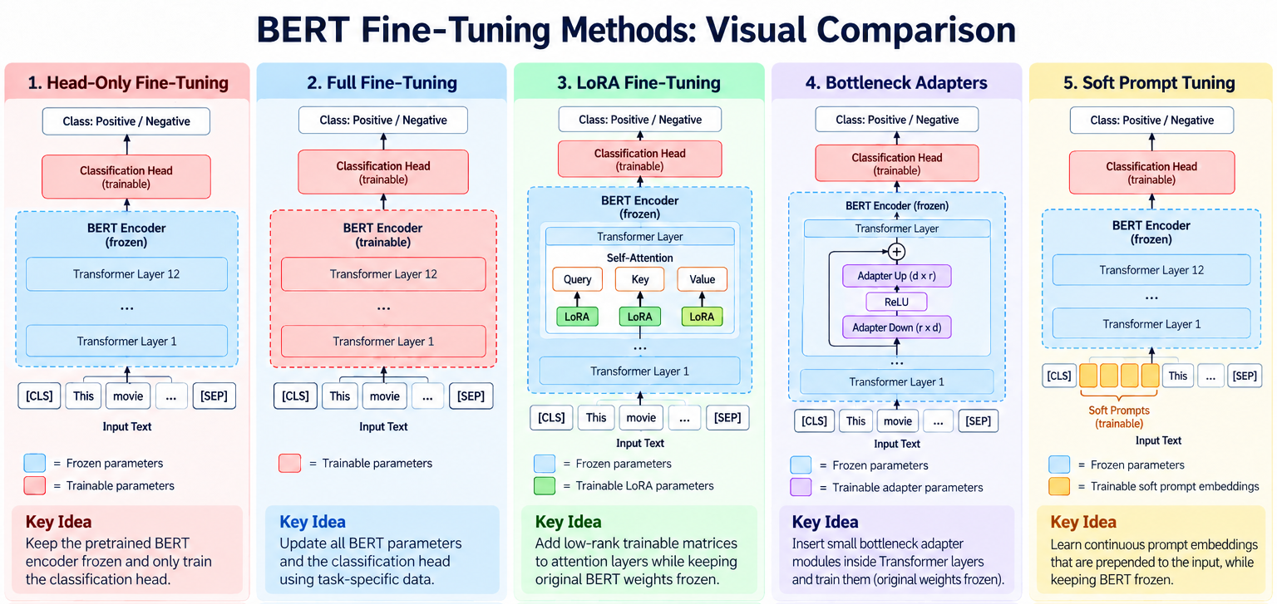


### **BERT for Sequence Classification**

BERT is a **bidirectional Transformer encoder** pretrained to learn contextual text representations.

For classification, the `[CLS]` representation is passed through a task-specific classification head.

$$
\mathbf{h}_{\mathrm{CLS}} = \mathrm{BERT}(x)_{\mathrm{CLS}}
$$

$$
\hat{\mathbf{y}} = \mathrm{softmax}(W\mathbf{h}_{\mathrm{CLS}} + b)
$$

**Training objective:** Cross-Entropy Loss.

**Key Question:** Which parameters should be updated to adapt BERT efficiently?


## **1. Experimental Setup**

We use the **SST-2 sentiment classification dataset** and a pretrained **BERT-base** model.

To ensure a fair comparison, all fine-tuning methods use:
- The same pretrained model and dataset splits.
- The same evaluation metric (Accuracy).
- Fresh model initialization for each experiment.

We compare **accuracy, trainable parameters, and computational cost**.

In [27]:
%pip install -q transformers datasets accelerate peft scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [28]:
import numpy as np
import torch

from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments,
    DataCollatorWithPadding
)
from sklearn.metrics import accuracy_score

MODEL_NAME = "bert-base-uncased"
SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)

In [29]:
dataset = load_dataset("nyu-mll/glue", "sst2")

train_ds = dataset["train"].shuffle(seed=SEED).select(range(1000))
val_ds = dataset["validation"].shuffle(seed=SEED).select(range(200))

print(train_ds[0])

{'sentence': 'klein , charming in comedies like american pie and dead-on in election , ', 'label': 1, 'idx': 32326}


### **Tokenization**

BERT processes token IDs rather than raw text.

**Input processing:**

`Text → WordPiece Tokens → Input IDs → BERT`

- `[CLS]`: Special token used for sequence classification.
- `[SEP]`: Marks the end of a sequence.
- `Attention Mask`: Distinguishes actual tokens from padding.

In [30]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize(batch):
    return tokenizer(
        batch["sentence"],
        truncation=True,
        max_length=128
    )

train_ds = train_ds.map(tokenize, batched=True)
val_ds = val_ds.map(tokenize, batched=True)

train_ds = train_ds.rename_column("label", "labels")
val_ds = val_ds.rename_column("label", "labels")

data_collator = DataCollatorWithPadding(tokenizer)

# Inspect tokenization
print(tokenizer.tokenize("This movie was fantastic!"))

['this', 'movie', 'was', 'fantastic', '!']


### **Model Initialization**

We load `bert-base-uncased` with a randomly initialized classification head.

**Architecture:**

`Input → BERT Encoder → [CLS] → Classification Head → Prediction`

Each fine-tuning method will start from a fresh pretrained BERT model.

In [31]:
def get_model():
    return AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=2
    )

model = get_model()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



### **Trainable Parameter Analysis**

A parameter is updated during training only if `requires_grad=True`.

$$
\text{Trainable (\%)} =
\frac{\text{Trainable Parameters}}{\text{Total Parameters}}
\times 100
$$

This allows us to measure the **parameter efficiency** of different fine-tuning methods.

In [32]:
def count_parameters(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )

    print(f"Total Parameters: {total:,}")
    print(f"Trainable Parameters: {trainable:,}")
    print(f"Trainable (%): {100 * trainable / total:.2f}%")

count_parameters(model)

Total Parameters: 109,483,778
Trainable Parameters: 109,483,778
Trainable (%): 100.00%


In [33]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    return {"accuracy": accuracy_score(labels, predictions)}

results = {}


## **2. Head-Only Fine-Tuning (Linear Probing)**

In **Head-Only Fine-Tuning**, the pretrained BERT encoder is frozen, and only the classification head is trained.

- **Frozen:** BERT embeddings and Transformer encoder layers.
- **Trainable:** Classification head.
- **Advantage:** Low computational cost and preserves pretrained representations.
- **Limitation:** Cannot adapt the BERT representations to the downstream task.

### Formulation

$$
\mathbf{h}_{\mathrm{CLS}} = f_{\theta_{\mathrm{BERT}}}(x)
$$

$$
\hat{\mathbf{y}} = \mathrm{softmax}(W_c\mathbf{h}_{\mathrm{CLS}} + b_c)
$$

**Optimization:**

$$
\theta_{\mathrm{BERT}} \text{ is frozen}, \qquad
\theta_{\mathrm{head}} \leftarrow
\theta_{\mathrm{head}}-\eta\nabla_{\theta_{\mathrm{head}}}\mathcal{L}
$$

In [34]:
model = get_model()

# Freeze pretrained BERT
for param in model.bert.parameters():
    param.requires_grad = False

# Classification head remains trainable
count_parameters(model)

# Verify trainable layers
for name, param in model.named_parameters():
    if param.requires_grad:
        print(name)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Total Parameters: 109,483,778
Trainable Parameters: 1,538
Trainable (%): 0.00%
classifier.weight
classifier.bias


In [35]:
head_args = TrainingArguments(
    output_dir="./results/head_only",
    learning_rate=1e-3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=3,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="no",
    logging_steps=20,
    report_to="none",
    seed=SEED,
)

head_trainer = Trainer(
    model=model,
    args=head_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

head_trainer.train()

/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/torch/utils/data/dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy
1,0.728933,0.666353,0.550000
2,0.665782,0.656473,0.580000
3,0.644798,0.648961,0.610000


/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/torch/utils/data/dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/torch/utils/data/dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


TrainOutput(global_step=189, training_loss=0.6772889258369567, metrics={'train_runtime': 12.8742, 'train_samples_per_second': 233.023, 'train_steps_per_second': 14.68, 'total_flos': 52942877670720.0, 'train_loss': 0.6772889258369567, 'epoch': 3.0})

In [36]:
metrics = head_trainer.evaluate()

results["Head-Only"] = {
    "accuracy": metrics["eval_accuracy"],
    "trainable_params": sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    ),
    "total_params": sum(p.numel() for p in model.parameters()),
}

print(f"Validation Accuracy: {metrics['eval_accuracy']:.4f}")

/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/torch/utils/data/dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy
0.644798,0.648961,3,0.610000


Validation Accuracy: 0.6100


In [37]:
texts = [
    "This movie was absolutely fantastic!",
    "The film was boring and disappointing.",
    "I really enjoyed the performances."
]

inputs = tokenizer(
    texts,
    padding=True,
    truncation=True,
    return_tensors="pt"
).to(model.device)

model.eval()
with torch.no_grad():
    predictions = model(**inputs).logits.argmax(dim=-1)

for text, pred in zip(texts, predictions):
    label = "Positive" if pred.item() == 1 else "Negative"
    print(f"{text} --> {label}")

This movie was absolutely fantastic! --> Positive
The film was boring and disappointing. --> Positive
I really enjoyed the performances. --> Positive



### Key Takeaway

- Only **1,538 parameters** are updated instead of approximately 109 million.
- BERT acts as a **frozen feature extractor**.
- The classification head learns to map pretrained representations to task labels.

**Question:** Can updating the entire BERT model improve task-specific representations and classification accuracy?


## **3. Full Fine-Tuning**

In **Full Fine-Tuning**, all pretrained BERT parameters and the classification head are updated using task-specific data.

- **Trainable:** Entire BERT encoder + classification head.
- **Advantage:** Allows all representations to adapt to the downstream task.
- **Limitation:** Higher computational and memory cost; potential catastrophic forgetting.

### Formulation

$$
\hat{\mathbf{y}} = \mathrm{softmax}(W_c f_{\theta}(x)_{\mathrm{CLS}} + b_c)
$$

**Optimization:**

$$
\theta' = \theta - \eta \nabla_{\theta}\mathcal{L}
$$

Unlike Head-Only training, gradients update both the **BERT backbone** and the **classification head**.

In [38]:
# Fresh pretrained model
model = get_model()

# All parameters are trainable by default
count_parameters(model)

# Verify trainable components
print("Embeddings:", model.bert.embeddings.word_embeddings.weight.requires_grad)
print("Encoder:", model.bert.encoder.layer[0].attention.self.query.weight.requires_grad)
print("Classifier:", model.classifier.weight.requires_grad)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Total Parameters: 109,483,778
Trainable Parameters: 109,483,778
Trainable (%): 100.00%
Embeddings: True
Encoder: True
Classifier: True


In [39]:
full_args = TrainingArguments(
    output_dir="./results/full_ft",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=3,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="no",
    logging_steps=20,
    report_to="none",
    seed=SEED,
)

full_trainer = Trainer(
    model=model,
    args=full_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

full_trainer.train()

/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/torch/utils/data/dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy
1,0.473561,0.388211,0.855000
2,0.332573,0.325941,0.870000
3,0.172187,0.312401,0.890000


/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/torch/utils/data/dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/torch/utils/data/dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


TrainOutput(global_step=189, training_loss=0.35023991645328584, metrics={'train_runtime': 82.768, 'train_samples_per_second': 36.246, 'train_steps_per_second': 2.283, 'total_flos': 52942877670720.0, 'train_loss': 0.35023991645328584, 'epoch': 3.0})

In [40]:
metrics = full_trainer.evaluate()

results["Full FT"] = {
    "accuracy": metrics["eval_accuracy"],
    "trainable_params": sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    ),
    "total_params": sum(p.numel() for p in model.parameters()),
}

print(f"Validation Accuracy: {metrics['eval_accuracy']:.4f}")

/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/torch/utils/data/dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy
0.172187,0.312401,3,0.890000


Validation Accuracy: 0.8900


In [41]:
import pandas as pd

comparison = pd.DataFrame(results).T

comparison["trainable_pct"] = (
    100 * comparison["trainable_params"] /
    comparison["total_params"]
)

display(comparison.round(4))

,accuracy,trainable_params,total_params,trainable_pct
Head-Only,0.61,1538.0,109483778.0,0.0014
Full FT,0.89,109483778.0,109483778.0,100.0000


### Key Takeaway

| Aspect | Head-Only | Full Fine-Tuning |
|---|---|---|
| BERT Encoder | Frozen | Trainable |
| Classification Head | Trainable | Trainable |
| Trainable Parameters | ~1.5K | ~109M |
| Memory Requirement | Lower | Higher |
| Representation Adaptation | No | Yes |

**Observation:** Full Fine-Tuning offers greater adaptation capacity, but requires updating millions of parameters.

**Question:** Can we achieve task-specific adaptation without updating the entire pretrained model?

→ **Next: Low-Rank Adaptation (LoRA)**

## **4. LoRA: Low-Rank Adaptation**

**LoRA** is a Parameter-Efficient Fine-Tuning (PEFT) technique that freezes pretrained weights and learns small, low-rank updates.

Instead of updating the original weight matrix $W$, LoRA learns two smaller matrices $A$ and $B$.

### Mathematical Formulation

$$
W' = W + \Delta W = W + BA
$$

where:

- $W \in \mathbb{R}^{d \times k}$: Frozen pretrained weights.
- $B \in \mathbb{R}^{d \times r}$, $A \in \mathbb{R}^{r \times k}$: Trainable low-rank matrices.
- $r \ll \min(d,k)$: Rank of the adaptation.

With scaling:

$$
h = Wx + \frac{\alpha}{r}BAx
$$

**Key Idea:** Train a small number of additional parameters while preserving the pretrained backbone.

In [42]:
%pip install -U "torchao>=0.16.0"

Note: you may need to restart the kernel to use updated packages.


In [43]:
from peft import LoraConfig, TaskType, get_peft_model

# Fresh pretrained BERT
model = get_model()

lora_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,
    r=8,
    lora_alpha=16,
    lora_dropout=0.1,
    target_modules=["query", "value"],
    modules_to_save=["classifier"],
    bias="none"
)

model = get_peft_model(model, lora_config)

count_parameters(model)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Total Parameters: 109,780,228
Trainable Parameters: 296,450
Trainable (%): 0.27%


In [44]:
for name, param in model.named_parameters():
    if param.requires_grad:
        print(name, param.shape)

base_model.model.bert.encoder.layer.0.attention.self.query.lora_A.default.weight torch.Size([8, 768])
base_model.model.bert.encoder.layer.0.attention.self.query.lora_B.default.weight torch.Size([768, 8])
base_model.model.bert.encoder.layer.0.attention.self.value.lora_A.default.weight torch.Size([8, 768])
base_model.model.bert.encoder.layer.0.attention.self.value.lora_B.default.weight torch.Size([768, 8])
base_model.model.bert.encoder.layer.1.attention.self.query.lora_A.default.weight torch.Size([8, 768])
base_model.model.bert.encoder.layer.1.attention.self.query.lora_B.default.weight torch.Size([768, 8])
base_model.model.bert.encoder.layer.1.attention.self.value.lora_A.default.weight torch.Size([8, 768])
base_model.model.bert.encoder.layer.1.attention.self.value.lora_B.default.weight torch.Size([768, 8])
base_model.model.bert.encoder.layer.2.attention.self.query.lora_A.default.weight torch.Size([8, 768])
base_model.model.bert.encoder.layer.2.attention.self.query.lora_B.default.weight t

In [45]:
lora_args = TrainingArguments(
    output_dir="./results/lora",
    learning_rate=5e-4,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=3,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="no",
    logging_steps=20,
    report_to="none",
    seed=SEED,
)

lora_trainer = Trainer(
    model=model,
    args=lora_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

lora_trainer.train()

/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/torch/utils/data/dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy
1,0.671999,0.544386,0.825000
2,0.438554,0.310005,0.880000
3,0.254511,0.294844,0.875000


/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/torch/utils/data/dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/torch/utils/data/dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


TrainOutput(global_step=189, training_loss=0.4674615254477849, metrics={'train_runtime': 25.0421, 'train_samples_per_second': 119.798, 'train_steps_per_second': 7.547, 'total_flos': 53126126459520.0, 'train_loss': 0.4674615254477849, 'epoch': 3.0})

In [46]:
metrics = lora_trainer.evaluate()

results["LoRA"] = {
    "accuracy": metrics["eval_accuracy"],
    "trainable_params": sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    ),
    "total_params": sum(p.numel() for p in model.parameters()),
}

print(f"Validation Accuracy: {metrics['eval_accuracy']:.4f}")

/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/torch/utils/data/dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy
0.254511,0.294844,3,0.875000


Validation Accuracy: 0.8750


In [47]:
model.save_pretrained("./saved_models/bert_lora")

In [48]:
import pandas as pd

comparison = pd.DataFrame(results).T

comparison["trainable_pct"] = (
    100 * comparison["trainable_params"] /
    comparison["total_params"]
)

display(comparison.round(4))

,accuracy,trainable_params,total_params,trainable_pct
Head-Only,0.610,1538.0,109483778.0,0.0014
Full FT,0.890,109483778.0,109483778.0,100.0000
LoRA,0.875,296450.0,109780228.0,0.2700



### Key Takeaway

- LoRA keeps the **pretrained BERT weights frozen**.
- Only low-rank matrices and the classification head are updated.
- Reduces trainable parameters and optimizer memory compared to Full Fine-Tuning.
- Enables storing multiple task-specific adaptations without duplicating the entire backbone.

### Discussion

**Head-Only vs. LoRA:** Both freeze the original BERT weights, but LoRA can adapt internal attention transformations.

**Full FT vs. LoRA:** Full FT updates the original weights, whereas LoRA learns low-rank updates.

**Question:** Can we achieve parameter-efficient adaptation using small neural networks inserted inside Transformer layers?

→ **Next: Bottleneck Adapters**


## **5. Bottleneck Adapters**

**Bottleneck Adapters** are a Parameter-Efficient Fine-Tuning (PEFT) technique that inserts small trainable neural networks inside pretrained Transformer layers.

The original BERT parameters remain frozen, while the adapters and classification head are trained.

### Mathematical Formulation

$$
\mathbf{h}' = \mathbf{h} +
W_{\mathrm{up}}\,\sigma(W_{\mathrm{down}}\mathbf{h})
$$

where:

- $W_{\mathrm{down}} \in \mathbb{R}^{r \times d}$: Down-projection.
- $W_{\mathrm{up}} \in \mathbb{R}^{d \times r}$: Up-projection.
- $r \ll d$: Bottleneck dimension.
- $\sigma$: Nonlinear activation.

**Key Idea:** Learn task-specific transformations through lightweight adapter modules without modifying pretrained BERT weights.

In [49]:
%pip install "huggingface-hub==0.36.2"

Note: you may need to restart the kernel to use updated packages.


In [50]:
%pip install -q adapters

Note: you may need to restart the kernel to use updated packages.


In [51]:
from adapters import AutoAdapterModel, SeqBnConfig

# Fresh pretrained BERT
model = AutoAdapterModel.from_pretrained(MODEL_NAME)

# Bottleneck adapter configuration
adapter_config = SeqBnConfig(
    reduction_factor=16
)

# Add adapter and classification head
model.add_adapter("sst2", config=adapter_config)
model.add_classification_head("sst2", num_labels=2)

# Freeze BERT, train adapter + classification head
model.train_adapter("sst2")
model.set_active_adapters("sst2")

count_parameters(model)

ImportError: cannot import name 'HfFolder' from 'huggingface_hub' (/opt/homebrew/Caskroom/miniforge/base/lib/python3.13/site-packages/huggingface_hub/__init__.py)

In [ ]:
for name, param in model.named_parameters():
    if param.requires_grad:
        print(name, param.shape)

bert.encoder.layer.0.output.adapters.sst2.adapter_down.0.weight torch.Size([48, 768])
bert.encoder.layer.0.output.adapters.sst2.adapter_down.0.bias torch.Size([48])
bert.encoder.layer.0.output.adapters.sst2.adapter_up.weight torch.Size([768, 48])
bert.encoder.layer.0.output.adapters.sst2.adapter_up.bias torch.Size([768])
bert.encoder.layer.1.output.adapters.sst2.adapter_down.0.weight torch.Size([48, 768])
bert.encoder.layer.1.output.adapters.sst2.adapter_down.0.bias torch.Size([48])
bert.encoder.layer.1.output.adapters.sst2.adapter_up.weight torch.Size([768, 48])
bert.encoder.layer.1.output.adapters.sst2.adapter_up.bias torch.Size([768])
bert.encoder.layer.2.output.adapters.sst2.adapter_down.0.weight torch.Size([48, 768])
bert.encoder.layer.2.output.adapters.sst2.adapter_down.0.bias torch.Size([48])
bert.encoder.layer.2.output.adapters.sst2.adapter_up.weight torch.Size([768, 48])
bert.encoder.layer.2.output.adapters.sst2.adapter_up.bias torch.Size([768])
bert.encoder.layer.3.output.ada

In [ ]:
train_ds = train_ds.remove_columns(["sentence", "idx"])
val_ds = val_ds.remove_columns(["sentence", "idx"])

print(train_ds.column_names)
# ['labels', 'input_ids', 'token_type_ids', 'attention_mask']

['labels', 'input_ids', 'token_type_ids', 'attention_mask']


In [ ]:
adapter_args = TrainingArguments(
    output_dir="./results/adapters",
    learning_rate=1e-4,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=3,
    eval_strategy="epoch",
    logging_strategy="epoch",
    label_names=["labels"],       # Important fix
    remove_unused_columns=False,
    save_strategy="no",
    report_to="none",
)

adapter_trainer = Trainer(
    model=model,
    args=adapter_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)
adapter_trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy
1,0.566700,0.342253,0.875000
2,0.355100,0.284712,0.895000
3,0.316500,0.273220,0.880000


TrainOutput(global_step=189, training_loss=0.4127510010250031, metrics={'train_runtime': 22.0631, 'train_samples_per_second': 135.974, 'train_steps_per_second': 8.566, 'total_flos': 54245783049600.0, 'train_loss': 0.4127510010250031, 'epoch': 3.0})

In [ ]:
metrics = adapter_trainer.evaluate()

results["Adapters"] = {
    "accuracy": metrics["eval_accuracy"],
    "trainable_params": sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    ),
    "total_params": sum(p.numel() for p in model.parameters()),
}

print(f"Validation Accuracy: {metrics['eval_accuracy']:.4f}")

Validation Accuracy: 0.8800


In [ ]:
model.save_adapter(
    "./saved_models/bert_adapter",
    "sst2",
    with_head=True
)

In [ ]:
import pandas as pd

comparison = pd.DataFrame(results).T

comparison["trainable_pct"] = (
    100 * comparison["trainable_params"]
    / comparison["total_params"]
)

display(comparison.round(4))

,accuracy,trainable_params,total_params,trainable_pct
Head-Only,0.615,1538.0,109483778.0,0.0014
Full FT,0.900,109483778.0,109483778.0,100.0000
LoRA,0.885,296450.0,109780228.0,0.2700
Adapters,0.880,2109308.0,111591548.0,1.8902



### Key Takeaway

- Bottleneck adapters introduce **small trainable neural networks** inside Transformer layers.
- The original BERT parameters remain frozen.
- Only adapter modules and the classification head are updated.

### LoRA vs. Bottleneck Adapters

| LoRA | Bottleneck Adapters |
|---|---|
| Low-rank weight updates | Additional neural network modules |
| Typically modifies attention projections | Operates on hidden representations |
| Linear low-rank update | Nonlinear bottleneck transformation |
| Can often be merged into base weights | Usually requires separate adapter computation |

**Question:** Can we adapt BERT without modifying its internal Transformer layers?

→ **Next: Soft Prompt Tuning**


## **6. Soft Prompt Tuning**

**Soft Prompt Tuning** adapts a pretrained model by learning a small set of continuous prompt embeddings instead of modifying the pretrained model weights.

- **Frozen:** Entire BERT backbone.
- **Trainable:** Soft prompt embeddings + classification head.
- **Advantage:** Extremely parameter-efficient.
- **Limitation:** Performance can be sensitive to prompt initialization and model size.

### Mathematical Formulation

Given input embeddings $X$ and trainable soft prompts $P$:

$$
P \in \mathbb{R}^{m \times d}
$$

$$
X' = [P;X]
$$

$$
\hat{y} = f_{\theta}(X')
$$

where $m$ is the number of virtual tokens and $d$ is the embedding dimension.

**Key Idea:** Learn task-specific input embeddings while keeping BERT's pretrained parameters frozen.

In [ ]:
import torch.nn as nn

class SoftPromptBERT(nn.Module):
    def __init__(self, num_virtual_tokens=10):
        super().__init__()

        self.bert_model = get_model()
        hidden_size = self.bert_model.config.hidden_size

        # Freeze pretrained BERT
        for param in self.bert_model.bert.parameters():
            param.requires_grad = False

        # Trainable virtual prompt embeddings
        self.soft_prompt = nn.Parameter(
            torch.randn(num_virtual_tokens, hidden_size) * 0.02
        )

        self.num_virtual_tokens = num_virtual_tokens

    def forward(self, input_ids, attention_mask,
                token_type_ids=None, labels=None):

        # Convert token IDs to embeddings
        embeddings = self.bert_model.bert.embeddings.word_embeddings(
            input_ids
        )

        batch_size = input_ids.size(0)

        # Expand virtual prompts across batch
        prompts = self.soft_prompt.unsqueeze(0).expand(
            batch_size, -1, -1
        )

        # Preserve [CLS] at position 0
        inputs_embeds = torch.cat(
            [embeddings[:, :1], prompts, embeddings[:, 1:]],
            dim=1
        )

        # Extend attention mask
        prompt_mask = attention_mask.new_ones(
            batch_size, self.num_virtual_tokens
        )

        attention_mask = torch.cat(
            [attention_mask[:, :1], prompt_mask,
             attention_mask[:, 1:]],
            dim=1
        )

        if token_type_ids is not None:
            prompt_types = token_type_ids.new_zeros(
                batch_size, self.num_virtual_tokens
            )
            token_type_ids = torch.cat(
                [token_type_ids[:, :1], prompt_types,
                 token_type_ids[:, 1:]],
                dim=1
            )

        return self.bert_model(
            inputs_embeds=inputs_embeds,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids,
            labels=labels
        )

In [ ]:
model = SoftPromptBERT(num_virtual_tokens=10)

count_parameters(model)

for name, param in model.named_parameters():
    if param.requires_grad:
        print(name, param.shape)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Total Parameters: 109,491,458
Trainable Parameters: 9,218
Trainable (%): 0.01%
soft_prompt torch.Size([10, 768])
bert_model.classifier.weight torch.Size([2, 768])
bert_model.classifier.bias torch.Size([2])


In [ ]:
prompt_args = TrainingArguments(
    output_dir="./results/soft_prompt",
    learning_rate=1e-3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=3,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="no",
    logging_steps=20,
    report_to="none",
    seed=SEED,
)

prompt_trainer = Trainer(
    model=model,
    args=prompt_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

prompt_trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy
1,0.724800,0.676192,0.575000
2,0.680000,0.653554,0.620000
3,0.643000,0.639620,0.590000


TrainOutput(global_step=189, training_loss=0.6783121124146476, metrics={'train_runtime': 22.6119, 'train_samples_per_second': 132.673, 'train_steps_per_second': 8.358, 'total_flos': 0.0, 'train_loss': 0.6783121124146476, 'epoch': 3.0})

In [ ]:
metrics = prompt_trainer.evaluate()

results["Soft Prompt"] = {
    "accuracy": metrics["eval_accuracy"],
    "trainable_params": sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    ),
    "total_params": sum(p.numel() for p in model.parameters()),
}

print(f"Validation Accuracy: {metrics['eval_accuracy']:.4f}")

Validation Accuracy: 0.5900


In [ ]:
torch.save({
    "soft_prompt": model.soft_prompt.detach().cpu(),
    "classifier": model.bert_model.classifier.state_dict()
}, "./soft_prompt_weights.pt")


### Key Takeaway

- Soft Prompt Tuning learns **continuous virtual token embeddings**.
- The pretrained BERT backbone remains completely frozen.
- Task adaptation occurs through the input embeddings rather than updates to internal Transformer weights.

### Comparison with Other PEFT Methods

| Method | Where Adaptation Happens |
|---|---|
| LoRA | Attention weight projections |
| Bottleneck Adapters | Hidden representations inside Transformer layers |
| Soft Prompt | Input embedding sequence |

**Observation:** Soft Prompt Tuning uses very few trainable parameters, but this does not guarantee higher accuracy or lower activation-memory usage.


## **7. Comparison of Fine-Tuning Methods**

We compare five fine-tuning strategies using the same BERT backbone and SST-2 dataset.

### Evaluation Criteria
- **Accuracy ($\uparrow$):** Classification performance on the validation set.
- **Trainable Parameters ($\downarrow$):** Number of parameters updated during training.
- **Parameter Efficiency:** Percentage of total model parameters that are trainable.

**Goal:** Understand the trade-off between task performance and parameter efficiency.

In [ ]:
import pandas as pd

df = pd.DataFrame(results).T

df["trainable_pct"] = (
    100 * df["trainable_params"] / df["total_params"]
)

df["trainable_M"] = df["trainable_params"] / 1e6

display(
    df[["accuracy", "trainable_params", "trainable_pct"]]
    .round(4)
)

,accuracy,trainable_params,trainable_pct
Head-Only,0.615,1538.0,0.0014
Full FT,0.900,109483778.0,100.0000
LoRA,0.885,296450.0,0.2700
Adapters,0.880,2109308.0,1.8902
Soft Prompt,0.590,9218.0,0.0084


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, LogLocator

df = pd.DataFrame(results).T.copy()
df["accuracy_pct"] = df["accuracy"] * 100
df["trainable_pct"] = (
    df["trainable_params"] / df["total_params"] * 100
)

order = ["Head-Only", "Full FT", "LoRA", "Adapters", "Soft Prompt"]
df = df.reindex([m for m in order if m in df.index])

# Consistent colors across visualizations
COLORS = {
    "Head-Only": "#64748B",
    "Full FT": "#2563EB",
    "LoRA": "#0D9488",
    "Adapters": "#8B5CF6",
    "Soft Prompt": "#F59E0B",
}

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 130,
    "savefig.dpi": 300,
})

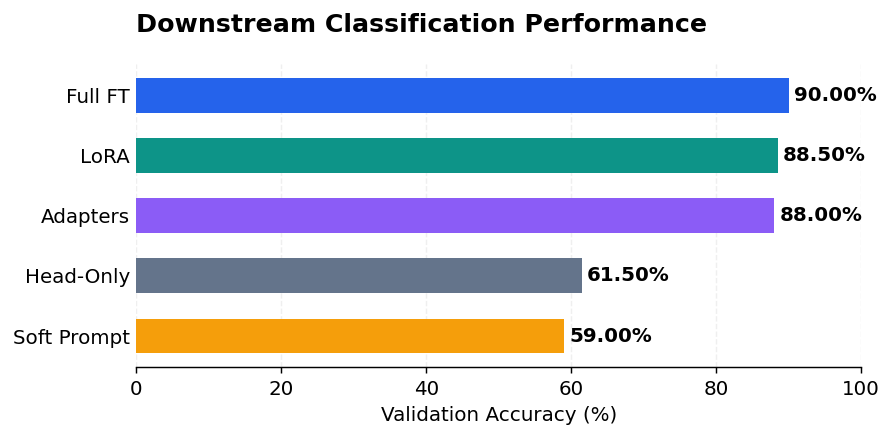

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.5))

plot_df = df.sort_values("accuracy_pct")
colors = [COLORS[m] for m in plot_df.index]

bars = ax.barh(
    plot_df.index,
    plot_df["accuracy_pct"],
    color=colors,
    height=0.58,
    edgecolor="none",
)

for bar, value in zip(bars, plot_df["accuracy_pct"]):
    ax.text(
        value + 0.7,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}%",
        va="center",
        fontsize=11,
        fontweight="bold"
    )

ax.set_xlim(0, max(100, plot_df["accuracy_pct"].max() + 8))
ax.set_xlabel("Validation Accuracy (%)")
ax.set_title("Downstream Classification Performance", loc="left", pad=18)

ax.xaxis.grid(True, linestyle="--", alpha=0.2)
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)

plt.tight_layout()
plt.show()

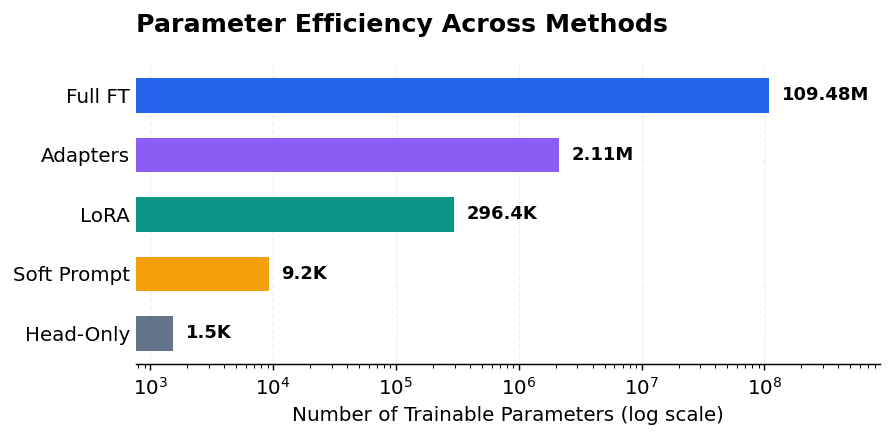

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.5))

plot_df = df.sort_values("trainable_params")
colors = [COLORS[m] for m in plot_df.index]

bars = ax.barh(
    plot_df.index,
    plot_df["trainable_params"],
    color=colors,
    height=0.58
)

def format_params(n):
    if n >= 1e6:
        return f"{n / 1e6:.2f}M"
    if n >= 1e3:
        return f"{n / 1e3:.1f}K"
    return f"{n:.0f}"

for bar, value in zip(bars, plot_df["trainable_params"]):
    ax.annotate(
        format_params(value),
        xy=(value, bar.get_y() + bar.get_height() / 2),
        xytext=(7, 0),
        textcoords="offset points",
        va="center",
        fontweight="bold",
        fontsize=10
    )

ax.set_xscale("log")
ax.set_xlim(
    plot_df["trainable_params"].min() / 2,
    plot_df["trainable_params"].max() * 8
)

ax.set_xlabel("Number of Trainable Parameters (log scale)")
ax.set_title("Parameter Efficiency Across Methods", loc="left", pad=18)

ax.xaxis.grid(True, which="major", linestyle="--", alpha=0.2)
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)

plt.tight_layout()
plt.show()

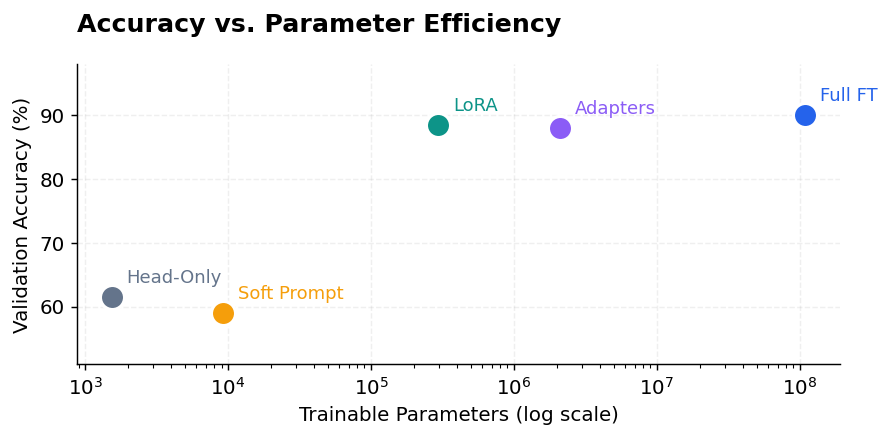

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.5))

for method, row in df.iterrows():
    x = row["trainable_params"]
    y = row["accuracy_pct"]

    ax.scatter(
        x, y,
        s=180,
        color=COLORS[method],
        edgecolor="white",
        linewidth=1.8,
        zorder=3
    )

    ax.annotate(
        method,
        (x, y),
        xytext=(8, 8),
        textcoords="offset points",
        fontsize=10,
        fontweight="medium",
        color=COLORS[method]
    )

ax.set_xscale("log")
ax.set_xlabel("Trainable Parameters (log scale)")
ax.set_ylabel("Validation Accuracy (%)")
ax.set_title(
    "Accuracy vs. Parameter Efficiency",
    loc="left",
    pad=18
)

ax.set_ylim(
    max(0, df["accuracy_pct"].min() - 8),
    min(100, df["accuracy_pct"].max() + 8)
)

ax.grid(True, linestyle="--", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


## 8. Key Takeaways

| Method | Main Idea | Trade-off |
|---|---|---|
| Head-Only | Train classifier, freeze backbone | Fast but limited adaptation |
| Full Fine-Tuning | Update all parameters | Flexible but expensive |
| LoRA | Learn low-rank weight updates | Efficient adaptation |
| Adapters | Insert trainable bottleneck modules | Modular, with some inference overhead |
| Soft Prompt | Learn virtual input embeddings | Very few trainable parameters |

### Discussion Questions

1. Does updating more parameters always improve accuracy?
2. Why can LoRA outperform Head-Only training despite freezing BERT?
3. Which method would you choose for training 100 different tasks?
4. Are fewer trainable parameters always equivalent to lower GPU memory usage?

### Conclusion

**Fine-tuning is a trade-off between adaptation capacity, computational efficiency, and downstream performance.**

There is no universally best method; the choice depends on the task, available resources, and performance requirements.